In [1]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())
os.makedirs("data/connectivity", exist_ok=True)

C:\Users\Alive\Documents\eeg-brain-networks-dementia


In [2]:
import mne, mne_connectivity
print(mne.__version__, mne_connectivity.__version__)

1.13.2 0.9.0


In [3]:
import numpy as np
from mne_connectivity import spectral_connectivity_epochs

FMIN = (1, 4, 8, 13, 30)
FMAX = (4, 8, 13, 30, 45)

def wpli_matrices(epochs):
    """Return an array (5 bands, 19, 19) of symmetric wPLI matrices."""
    con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
                                       fmin=FMIN, fmax=FMAX, faverage=True, verbose=False)
    m = con.get_data(output="dense")          # 19 x 19 x 5, lower triangle only
    m = np.moveaxis(m, -1, 0)                 # -> 5 x 19 x 19
    m = m + np.transpose(m, (0, 2, 1))        # make symmetric
    for b in range(m.shape[0]):
        np.fill_diagonal(m[b], 0)
    return m

ep = mne.read_epochs("data/epochs/sub-001-epo.fif", preload=True, verbose=False)
W = wpli_matrices(ep)
print(W.shape, W.min().round(3), W.max().round(3))
print("Symmetric:", np.allclose(W[2], W[2].T))
print("Mean wPLI per band:", W.mean(axis=(1, 2)).round(3))

C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\2117687711.py:9: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\2117687711.py:9: RuntimeWarning: fmin=1.000 Hz corresponds to 4.000 < 5 cycles based on the epoch length 4.000 sec, need at least 5.000 sec epochs or fmin=1.250. Spectrum estimate will be unreliable.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


(5, 19, 19) 0.0 0.621
Symmetric: True
Mean wPLI per band: [0.155 0.193 0.178 0.166 0.225]


In [4]:
import numpy as np, mne
from mne_connectivity import spectral_connectivity_epochs

BAND_NAMES = ["delta", "theta", "alpha", "beta", "gamma"]
FMIN = (1.25, 4, 8, 13, 30)
FMAX = (4, 8, 13, 30, 45)

def wpli_matrices(epochs):
    """Return an array (5 bands, 19, 19) of symmetric wPLI matrices."""
    con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
                                       fmin=FMIN, fmax=FMAX, faverage=True, verbose=False)
    m = con.get_data(output="dense")
    m = np.moveaxis(m, -1, 0)
    m = m + np.transpose(m, (0, 2, 1))
    for b in range(m.shape[0]):
        np.fill_diagonal(m[b], 0)
    return m

offdiag = ~np.eye(19, dtype=bool)
for sub in ["sub-001", "sub-037", "sub-066"]:
    ep = mne.read_epochs(f"data/epochs/{sub}-epo.fif", preload=True, verbose=False)
    W = wpli_matrices(ep)
    np.save(f"data/connectivity/{sub}_wpli.npy", W)
    means = [W[b][offdiag].mean().round(3) for b in range(5)]
    print(sub, W.shape, "range", W.min().round(3), W.max().round(3),
          "| symmetric:", all(np.allclose(W[b], W[b].T) for b in range(5)),
          "| off-diagonal means:", means)

C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\105472964.py:10: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


sub-001 (5, 19, 19) range 0.0 0.621 | symmetric: True | off-diagonal means: [np.float64(0.159), np.float64(0.203), np.float64(0.188), np.float64(0.176), np.float64(0.238)]


C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\105472964.py:10: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


sub-037 (5, 19, 19) range 0.0 0.65 | symmetric: True | off-diagonal means: [np.float64(0.147), np.float64(0.207), np.float64(0.308), np.float64(0.153), np.float64(0.136)]
sub-066 (5, 19, 19) range 0.0 0.491 | symmetric: True | off-diagonal means: [np.float64(0.138), np.float64(0.19), np.float64(0.209), np.float64(0.174), np.float64(0.196)]


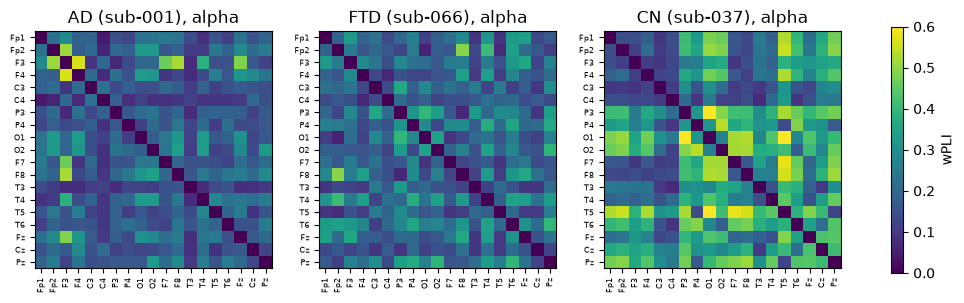

In [5]:
import matplotlib.pyplot as plt
os.makedirs("results/figures", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (sub, grp) in zip(axes, [("sub-001", "AD"), ("sub-066", "FTD"), ("sub-037", "CN")]):
    W = np.load(f"data/connectivity/{sub}_wpli.npy")
    im = ax.imshow(W[2], vmin=0, vmax=0.6, cmap="viridis")
    ax.set_title(f"{grp} ({sub}), alpha")
    ax.set_xticks(range(19)); ax.set_yticks(range(19))
    ax.set_xticklabels(ep.ch_names, rotation=90, fontsize=6)
    ax.set_yticklabels(ep.ch_names, fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8, label="wPLI")
plt.savefig("results/figures/test_subjects_wpli_alpha.png", dpi=150, bbox_inches="tight")
plt.show()

In [1]:
import os
from pathlib import Path
root = Path.cwd()
while not (root / ".git").exists():
    root = root.parent
os.chdir(root)
print(os.getcwd())
print(os.listdir("src"))
os.makedirs("data/connectivity", exist_ok=True)

c:\Users\Alive\Documents\eeg-brain-networks-dementia
['.gitkeep', 'connectivity.py', 'epoching.py', 'spectral.py', '__pycache__']


In [2]:
%%writefile src/connectivity.py
import numpy as np
from mne_connectivity import spectral_connectivity_epochs

BAND_NAMES = ["delta", "theta", "alpha", "beta", "gamma"]
FMIN = (1.25, 4, 8, 13, 30)   # delta starts at 1.25 Hz: 4-s epochs hold < 5 cycles at 1 Hz
FMAX = (4, 8, 13, 30, 45)


def wpli_matrices(epochs):
    """Return an array (5 bands, 19, 19) of symmetric wPLI matrices."""
    con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
                                       fmin=FMIN, fmax=FMAX, faverage=True, verbose=False)
    m = con.get_data(output="dense")
    m = np.moveaxis(m, -1, 0)
    m = m + np.transpose(m, (0, 2, 1))
    for b in range(m.shape[0]):
        np.fill_diagonal(m[b], 0)
    return m

Overwriting src/connectivity.py


In [3]:
import sys, warnings
import numpy as np, pandas as pd, mne
sys.path.append("src")
import connectivity
mne.set_log_level("ERROR")
warnings.filterwarnings("ignore", message="There were no Annotations")

df = pd.read_csv("data/ds004504/participants.tsv", sep="\t")
offdiag = ~np.eye(19, dtype=bool)
rows = []
for k, sub in enumerate(df["participant_id"], 1):
    f = f"data/epochs/{sub}-epo.fif"
    out = f"data/connectivity/{sub}_wpli.npy"
    if not os.path.exists(f):
        print(f"[{k}/88] skipping {sub} (no epoch file)")
        continue
    if os.path.exists(out):
        W = np.load(out)
    else:
        ep = mne.read_epochs(f, preload=True, verbose=False)
        W = connectivity.wpli_matrices(ep)
        np.save(out, W)
    ok = (W.shape == (5, 19, 19)) and np.isfinite(W).all() and W.min() >= 0 and W.max() <= 1 \
         and all(np.allclose(W[b], W[b].T) for b in range(5))
    rows.append(dict(participant_id=sub, ok=ok, **{f"mean_{b}": W[i][offdiag].mean()
                 for i, b in enumerate(connectivity.BAND_NAMES)}))
    print(f"[{k}/88] {sub} ok={ok}")

chk = pd.DataFrame(rows).merge(df[["participant_id", "Group"]], on="participant_id")
chk.to_csv("results/tables/wpli_mean_check.csv", index=False)
print(chk.ok.value_counts())
print(chk.groupby("Group")[[c for c in chk.columns if c.startswith("mean_")]].median().round(3))

[1/88] sub-001 ok=True
[2/88] sub-002 ok=True
[3/88] sub-003 ok=True
[4/88] sub-004 ok=True
[5/88] sub-005 ok=True
[6/88] sub-006 ok=True
[7/88] sub-007 ok=True
[8/88] sub-008 ok=True
[9/88] sub-009 ok=True
[10/88] sub-010 ok=True
[11/88] sub-011 ok=True
[12/88] sub-012 ok=True
[13/88] sub-013 ok=True
[14/88] sub-014 ok=True
[15/88] sub-015 ok=True
[16/88] sub-016 ok=True
[17/88] sub-017 ok=True
[18/88] sub-018 ok=True
[19/88] sub-019 ok=True
[20/88] sub-020 ok=True
[21/88] sub-021 ok=True
[22/88] sub-022 ok=True
[23/88] sub-023 ok=True
[24/88] sub-024 ok=True
[25/88] sub-025 ok=True
[26/88] sub-026 ok=True
[27/88] sub-027 ok=True
[28/88] sub-028 ok=True
[29/88] sub-029 ok=True
[30/88] sub-030 ok=True
[31/88] sub-031 ok=True
[32/88] sub-032 ok=True
[33/88] sub-033 ok=True
[34/88] sub-034 ok=True
[35/88] sub-035 ok=True
[36/88] sub-036 ok=True
[37/88] sub-037 ok=True
[38/88] sub-038 ok=True
[39/88] sub-039 ok=True
[40/88] sub-040 ok=True
[41/88] sub-041 ok=True
[42/88] sub-042 ok=True
[

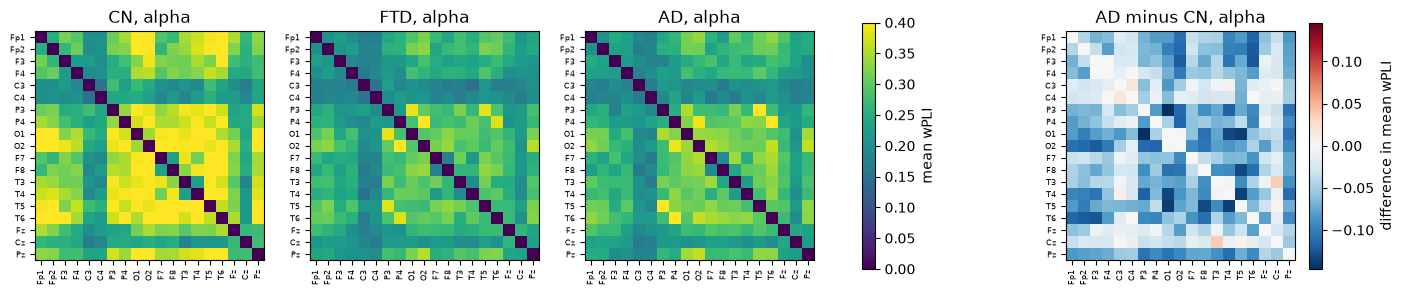

In [4]:
import matplotlib.pyplot as plt
ch_names = mne.read_epochs("data/epochs/sub-001-epo.fif", verbose=False).ch_names

def group_mean(g, band=2):
    subs = df.loc[df.Group == g, "participant_id"]
    mats = [np.load(f"data/connectivity/{s}_wpli.npy")[band] for s in subs
            if os.path.exists(f"data/connectivity/{s}_wpli.npy")]
    return np.mean(mats, axis=0)

M = {g: group_mean(g) for g in ["C", "F", "A"]}
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (g, title) in zip(axes[:3], [("C", "CN"), ("F", "FTD"), ("A", "AD")]):
    im = ax.imshow(M[g], vmin=0, vmax=0.4, cmap="viridis")
    ax.set_title(f"{title}, alpha")
fig.colorbar(im, ax=axes[:3], shrink=0.8, label="mean wPLI")
diff = M["A"] - M["C"]
lim = np.abs(diff).max()
im2 = axes[3].imshow(diff, vmin=-lim, vmax=lim, cmap="RdBu_r")
axes[3].set_title("AD minus CN, alpha")
fig.colorbar(im2, ax=axes[3], shrink=0.8, label="difference in mean wPLI")
for ax in axes:
    ax.set_xticks(range(19)); ax.set_yticks(range(19))
    ax.set_xticklabels(ch_names, rotation=90, fontsize=6)
    ax.set_yticklabels(ch_names, fontsize=6)
plt.savefig("results/figures/group_wpli_alpha.png", dpi=150, bbox_inches="tight")
plt.show()